In [19]:
from openfermion import FermionOperator, QubitOperator, jordan_wigner, lambda_norm, hermitian_conjugated
from openfermion import hermitian_conjugated, normal_ordered, get_sparse_operator
import matplotlib.pyplot as plt

In [20]:
initial_state = QubitOperator('X0')
measure_op = QubitOperator('Z0')

initial_sparse:  1.0


(-1.01, 1.01)

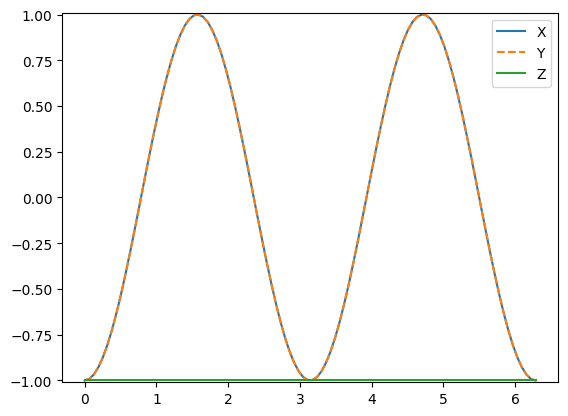

In [21]:
import numpy as np
from scipy.sparse.linalg import expm, expm_multiply


initial_sparse = get_sparse_operator(initial_state, n_qubits=1)
measure_sparse = get_sparse_operator(measure_op, n_qubits=1)


dot = (initial_sparse.T.conj() @ initial_sparse)[0, 0].real
print('initial_sparse: ', dot)

measure_x = []
measure_y = []
measure_z = []

range_x = np.linspace(0, 2*np.pi, 100)
for a in range_x:
    generator = -1j * a * QubitOperator('X0')
    sparse_gen = get_sparse_operator(generator, n_qubits=1)
    state = expm_multiply(sparse_gen, initial_sparse)
    dot = (state.T.conj() @ measure_sparse @ state)[0, 0].real
    measure_x.append(dot)

    generator = -1j * a * QubitOperator('Y0')
    sparse_gen = get_sparse_operator(generator, n_qubits=1)
    state = expm_multiply(sparse_gen, initial_sparse)
    dot = (state.T.conj() @ measure_sparse @ state)[0, 0].real
    measure_y.append(dot)

    generator = 1j * a * QubitOperator('Z0')
    sparse_gen = get_sparse_operator(generator, n_qubits=1)
    state = expm_multiply(sparse_gen, initial_sparse)
    dot = (state.T.conj() @ measure_sparse @ state)[0, 0].real
    measure_z.append(dot)

import matplotlib.pyplot as plt

plt.plot(range_x, measure_x, label='X')
plt.plot(range_x, measure_y, '--', label='Y')
plt.plot(range_x, measure_z, label='Z')
plt.legend()

plt.ylim(-1.01, 1.01)

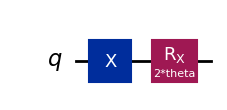

In [22]:
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector, Parameter

# Define the variational parameter
theta = Parameter("theta")

# Build the ansatz
qc_x = QuantumCircuit(1)

qc_x.x(0)

qc_x.rx(2*theta, 0)

qc_x.draw('mpl')

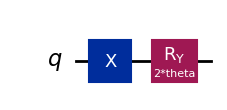

In [23]:
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector, Parameter

# Define the variational parameter
theta = Parameter("theta")

# Build the ansatz
qc_y = QuantumCircuit(1)
qc_y.x(0)

qc_y.ry(2*theta, 0)

qc_y.draw('mpl')

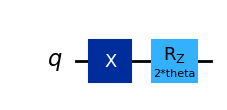

In [24]:
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector, Parameter

# Define the variational parameter
theta = Parameter("theta")

# Build the ansatz
qc_z = QuantumCircuit(1)
qc_z.x(0)

qc_z.rz(2*theta, 0)

qc_z.draw('mpl')

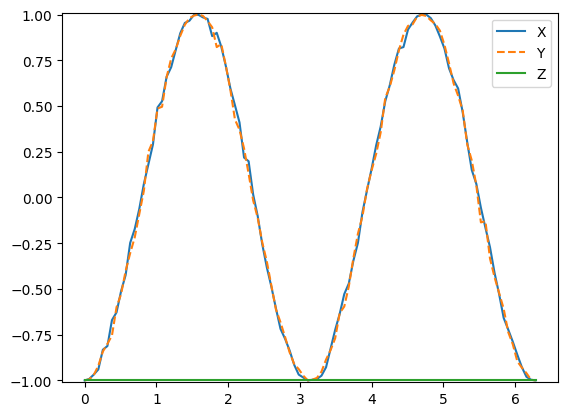

In [25]:
from qiskit.primitives import StatevectorSampler


def get_expectation(qc):
    dot_x = []
    range_x = np.linspace(0, 2*np.pi, 100)
    for a in range_x:

        # create circuit
        qc_meas = qc.assign_parameters([a])

        # change of basis
        #qc_meas.h(0)  # measure X
        #qc_meas.rx(np.pi / 2, 0)  # measure y

        # add measure
        qc_meas.measure_all()

        # Sample
        sampler = StatevectorSampler()

        result = sampler.run([qc_meas], shots=1000).result()
        counts = result[0].data.meas.get_counts()

        n_shots = sum(counts.values())

        prob_0 = counts.get('0', 0)/n_shots
        prob_1 = counts.get('1', 0)/n_shots

        measure = (+1 * prob_0
                   -1 * prob_1)

        dot_x.append(measure)

    return dot_x


value_x = get_expectation(qc_x)
value_y = get_expectation(qc_y)
value_z = get_expectation(qc_z)


import matplotlib.pyplot as plt

plt.plot(range_x, value_x, label='X')
plt.plot(range_x, value_y, '--', label='Y')
plt.plot(range_x, value_z, label='Z')

plt.ylim(-1.01, 1.01)
plt.legend()


2 qubits
--------

In [26]:
initial_state = QubitOperator('X0 X1')
measure_op = QubitOperator('X0 Y1')

initial_sparse:  1.0


(-1.01, 1.01)

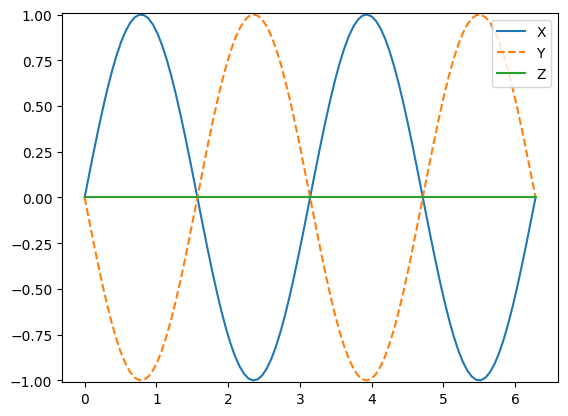

In [27]:
import numpy as np
from scipy.sparse.linalg import expm, expm_multiply


initial_sparse = get_sparse_operator(initial_state, n_qubits=2)
measure_sparse = get_sparse_operator(measure_op, n_qubits=2)


dot = (initial_sparse.T.conj() @ initial_sparse)[0, 0].real
print('initial_sparse: ', dot)

measure_x = []
measure_y = []
measure_z = []

range_x = np.linspace(0, 2*np.pi, 100)
for a in range_x:
    generator = -1j * a * QubitOperator('X0 X1')
    sparse_gen = get_sparse_operator(generator, n_qubits=2)
    state = expm_multiply(sparse_gen, initial_sparse)
    dot = (state.T.conj() @ measure_sparse @ state)[0, 0].real
    measure_x.append(dot)

    generator = -1j * a * QubitOperator('Y0 Y1')
    sparse_gen = get_sparse_operator(generator, n_qubits=2)
    state = expm_multiply(sparse_gen, initial_sparse)
    dot = (state.T.conj() @ measure_sparse @ state)[0, 0].real
    measure_y.append(dot)

    generator = -1j * a * QubitOperator('Z0 Z1')
    sparse_gen = get_sparse_operator(generator, n_qubits=2)
    state = expm_multiply(sparse_gen, initial_sparse)
    dot = (state.T.conj() @ measure_sparse @ state)[0, 0].real
    measure_z.append(dot)

import matplotlib.pyplot as plt

plt.plot(range_x, measure_x, label='X')
plt.plot(range_x, measure_y, '--', label='Y')
plt.plot(range_x, measure_z, label='Z')
plt.legend()

plt.ylim(-1.01, 1.01)

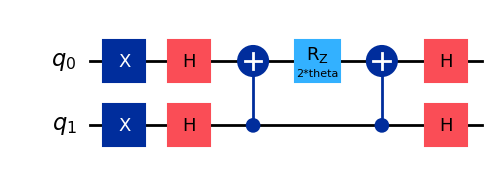

In [28]:
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector, Parameter

# Define the variational parameter
theta = Parameter("theta")

# Build the ansatz
qc_x = QuantumCircuit(2)

# reference state
qc_x.x(0)
qc_x.x(1)

# basis change
qc_x.h(0)
qc_x.h(1)

qc_x.cx(1, 0)
qc_x.rz(2*theta, 0)
qc_x.cx(1, 0)

# restore basis
qc_x.h(0)
qc_x.h(1)


qc_x.draw('mpl')

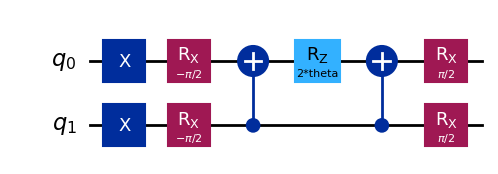

In [29]:
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector, Parameter

# Define the variational parameter
theta = Parameter("theta")

# Build the ansatz
qc_y = QuantumCircuit(2)

# reference state
qc_y.x(0)
qc_y.x(1)

# basis change
qc_y.rx(-np.pi / 2, 0)  # measure y
qc_y.rx(-np.pi / 2, 1)  # measure y

qc_y.cx(1, 0)
qc_y.rz(2*theta, 0)
qc_y.cx(1, 0)

# restore basis
qc_y.rx(np.pi / 2, 0)  # measure y
qc_y.rx(np.pi / 2, 1)  # measure y


qc_y.draw('mpl')

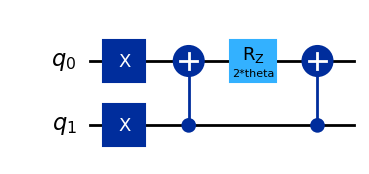

In [30]:
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector, Parameter

# Define the variational parameter
theta = Parameter("theta")

# Build the ansatz
qc_z = QuantumCircuit(2)

# reference state
qc_z.x(0)
qc_z.x(1)

qc_z.cx(1, 0)
qc_z.rz(2*theta, 0)
qc_z.cx(1, 0)

qc_z.draw('mpl')

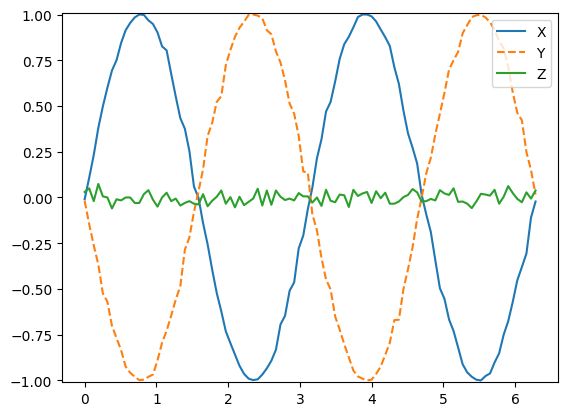

In [31]:
from qiskit.primitives import StatevectorSampler


def get_expectation(qc):
    measures = []
    range_x = np.linspace(0, 2*np.pi, 100)
    for a in range_x:

        # create circuit
        qc_meas = qc.assign_parameters([a]).copy()

        # change of basis
        qc_meas.h(0)  # measure X
        qc_meas.rx(np.pi / 2, 1)  # measure y

        # add measure
        qc_meas.measure_all()

        # Sample
        sampler = StatevectorSampler()

        result = sampler.run([qc_meas], shots=1000).result()
        counts = result[0].data.meas.get_counts()

        n_shots = sum(counts.values())

        prob_00 = counts.get('00', 0)/n_shots
        prob_01 = counts.get('01', 0)/n_shots
        prob_10 = counts.get('10', 0)/n_shots
        prob_11 = counts.get('11', 0)/n_shots

        # print(prob_00, prob_01, prob_10, prob_11)

        measure = (+1 * prob_11  # -1 * -1
                   -1 * prob_10  # -1 * +1
                   -1 * prob_01  # +1 * -1
                   +1 * prob_00) # +1 * +1

        measures.append(measure)

    return measures

value_x = get_expectation(qc_x)
value_y = get_expectation(qc_y)
value_z = get_expectation(qc_z)

import matplotlib.pyplot as plt

plt.plot(range_x, value_x, label='X')
plt.plot(range_x, value_y, '--', label='Y')
plt.plot(range_x, value_z, label='Z')

plt.ylim(-1.01, 1.01)
plt.legend()

- test using different operators for measurement and evolution and convince yourself that the algorithm is correct
- Test an example with 3 qubits
- Test and example with two rotations assuming trotterization (ref * e^A * e^B)

3 quits
-------

In [32]:
initial_state = QubitOperator('X1 X2')
measure_op = QubitOperator('Z0 Z1 Z2')

initial_sparse:  1.0


(-1.01, 1.01)

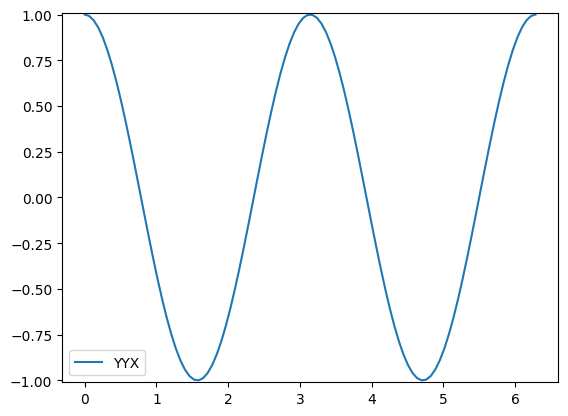

In [33]:
import numpy as np
from scipy.sparse.linalg import expm, expm_multiply


initial_sparse = get_sparse_operator(initial_state, n_qubits=3)
measure_sparse = get_sparse_operator(measure_op, n_qubits=3)


dot = (initial_sparse.T.conj() @ initial_sparse)[0, 0].real
print('initial_sparse: ', dot)

measure = []

range_x = np.linspace(0, 2*np.pi, 100)
for a in range_x:
    generator = -1j * a * QubitOperator('Y0 Y1 X2')
    sparse_gen = get_sparse_operator(generator, n_qubits=3)
    state = expm_multiply(sparse_gen, initial_sparse)
    dot = (state.T.conj() @ measure_sparse @ state)[0, 0].real
    measure.append(dot)

import matplotlib.pyplot as plt

plt.plot(range_x, measure, label='YYX')
plt.legend()

plt.ylim(-1.01, 1.01)

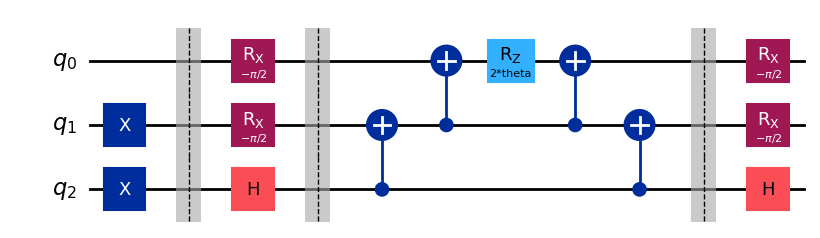

In [34]:
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector, Parameter

# Define the variational parameter
theta = Parameter("theta")

# Build the ansatz
qc_yyx = QuantumCircuit(3)

# reference state
qc_yyx.x(1)
qc_yyx.x(2)

qc_yyx.barrier()

# basis change
qc_yyx.rx(-np.pi / 2, 0)  # measure y
qc_yyx.rx(-np.pi / 2, 1)  # measure y
qc_yyx.h(2)

qc_yyx.barrier()

qc_yyx.cx(2, 1)
qc_yyx.cx(1, 0)
qc_yyx.rz(2*theta, 0)
qc_yyx.cx(1, 0)
qc_yyx.cx(2, 1)

qc_yyx.barrier()

# restore basis
qc_yyx.h(2)
qc_yyx.rx(-np.pi / 2, 1)  # measure y
qc_yyx.rx(-np.pi / 2, 0)  # measure y

qc_yyx.draw('mpl')

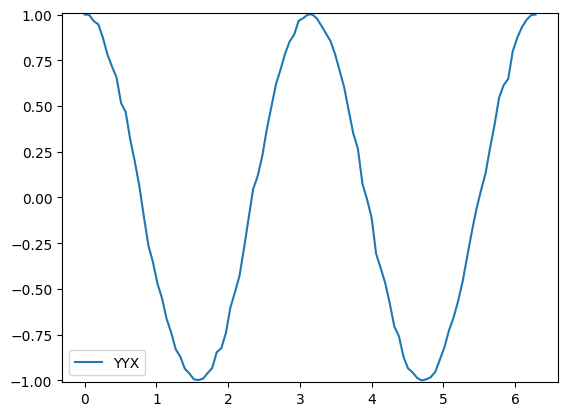

In [35]:
from qiskit.primitives import StatevectorSampler


def get_expectation(qc):
    measures = []
    range_x = np.linspace(0, 2*np.pi, 100)
    for a in range_x:

        # create circuit
        qc_meas = qc.assign_parameters([a]).copy()

        # change of basis
        #qc_meas.h(0)  # measure X
        #qc_meas.rx(np.pi / 2, 1)  # measure y

        # add measure
        qc_meas.measure_all()

        # Sample
        sampler = StatevectorSampler()

        result = sampler.run([qc_meas], shots=1000).result()
        counts = result[0].data.meas.get_counts()

        n_shots = sum(counts.values())

        prob_000 = counts.get('000', 0)/n_shots
        prob_001 = counts.get('001', 0)/n_shots
        prob_010 = counts.get('010', 0)/n_shots
        prob_011 = counts.get('011', 0)/n_shots

        prob_100 = counts.get('100', 0)/n_shots
        prob_101 = counts.get('101', 0)/n_shots
        prob_110 = counts.get('110', 0)/n_shots
        prob_111 = counts.get('111', 0)/n_shots


        measure = (+1 * prob_011  # +1 * -1 * -1
                   -1 * prob_010  # +1 * -1 * +1
                   -1 * prob_001  # +1 * +1 * -1
                   +1 * prob_000  # +1 * +1 * +1

                   -1 * prob_111  # -1 * -1 * -1
                   +1 * prob_110  # -1 * -1 * +1
                   +1 * prob_101  # -1 * +1 * -1
                   -1 * prob_100  # -1 * +1 * +1

                   )

        measures.append(measure)

    return measures

value_yyx = get_expectation(qc_yyx)

import matplotlib.pyplot as plt

plt.plot(range_x, value_yyx, label='YYX')

plt.ylim(-1.01, 1.01)
plt.legend()